<a href="https://colab.research.google.com/github/paviayyala/AIML-Lab/blob/main/Catch_the_fraudster.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup done ✅
Total accounts: 1000


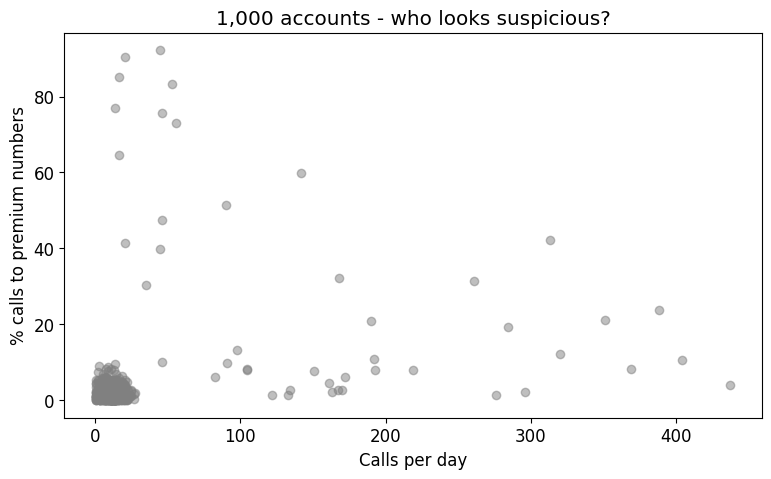

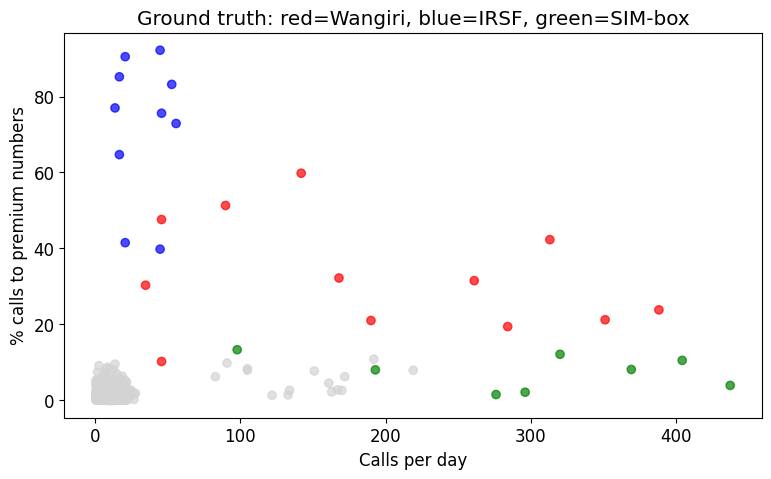

fraud_type
none       970
wangiri     12
irsf        10
simbox       8
Name: count, dtype: int64
Accounts flagged by the model: 30
✅ Fraudsters caught : 29 of 30
⚠️  False alarms      : 1  (innocent people flagged)
❌ Fraudsters missed : 1

Precision (of flagged, how many are real fraud): 97%
Recall    (of real fraud, how many we caught)  : 97%

Catch rate by fraud type:
fraud_type
irsf       100%
simbox     100%
wangiri     92%
Name: flagged, dtype: object


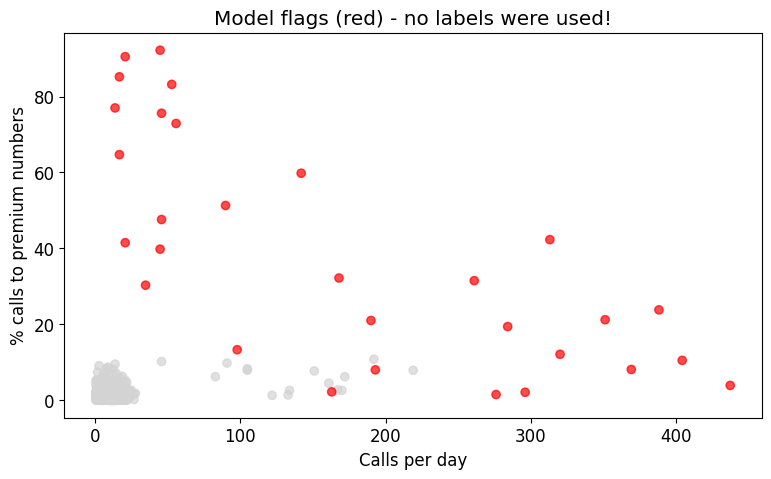


Account: FRD_wangiri_9
Calls per day: 388   (typical customer: ~12)
Average call duration: 55 seconds   (typical: ~180)
Night-time calls: 44%   (typical: ~14%)
Calls to premium-rate numbers: 24%   (typical: ~2%)
Unique numbers called per day: 330

------------------------------------------------------------
📄 Offline fallback note (no API key or API unavailable)
Account FRD_wangiri_9 shows 388 calls/day at 55s average duration with 24% to premium numbers, far outside normal behaviour. Pattern is consistent with premium-rate or short-duration call abuse. Risk: HIGH. Recommended action: apply a temporary outbound premium-rate block, flag for analyst review within 24 hours, and contact the customer to verify the activity.


In [3]:
# ##### (Optional) TEXT cell: paste into a new TEXT cell #####
# # 🕵️ Catch the Fraudster: Data → ML → GenAI
# **Story:** A telecom operator is losing money to fraud. We have 1,000 customer accounts. Can we find the ~30 fraudsters hiding among them?
#
# We'll go through the full arc in one notebook:
# 1. **Data**: explore messy account behaviour
# 2. **ML**: detect anomalies with Isolation Forest
# 3. **GenAI**: have an LLM write the fraud analyst's case note


# ##### >>> COLAB CELL 1: paste into a new CODE cell <<<
# ============ CELL 1: SETUP ============
# Install the Anthropic library (only needed for the GenAI step at the end).
!pip install -q anthropic

# pandas = tables, numpy = numbers/random data, matplotlib = charts
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make charts a bit bigger and cleaner for the screen share
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 12
print("Setup done ✅")


# ##### (Optional) TEXT cell: paste into a new TEXT cell #####
# ## Step 1: The data
# In real life this comes from call records (CDRs). Here we **generate synthetic data** so no real customer data is ever used.
# We plant 3 well-known fraud patterns among normal customers.


# ##### >>> COLAB CELL 2: paste into a new CODE cell <<<
# ============ CELL 2: GENERATE SYNTHETIC TELECOM DATA ============
# A fixed random seed means everyone gets the SAME data (important for a live demo!)
rng = np.random.default_rng(42)

# ---------- 955 NORMAL customers ----------
n = 955
calls = rng.normal(12, 5, n).clip(1, 40).round()          # ~12 calls/day on average
normal = pd.DataFrame({
    'account_id': [f'ACC{i:04d}' for i in range(n)],
    'calls_per_day': calls,
    'avg_duration_sec': rng.normal(180, 60, n).clip(20, 900).round(),   # ~3 minute calls
    'night_call_pct': (rng.beta(2, 12, n) * 100).round(1),              # few night calls
    'premium_dest_pct': (rng.beta(1, 60, n) * 100).round(1),            # almost no premium numbers
    'unique_destinations': (calls * rng.uniform(0.3, 0.8, n)).round().clip(1),  # people call the same folks repeatedly
    'is_fraud': 0,
    'fraud_type': 'none'
})

# ---------- 15 legit BUSINESS accounts (call-centres etc.): unusual but NOT fraud ----------
# Real life is messy: some innocent customers look odd too, which creates false alarms.
nb_ = 15
biz = pd.DataFrame({
    'account_id': [f'BIZ{i:03d}' for i in range(nb_)],
    'calls_per_day': rng.uniform(80, 220, nb_).round(),
    'avg_duration_sec': rng.uniform(40, 300, nb_).round(),
    'night_call_pct': rng.uniform(2, 35, nb_).round(1),
    'premium_dest_pct': rng.uniform(0, 12, nb_).round(1),
    'unique_destinations': rng.uniform(25, 120, nb_).round(),
    'is_fraud': 0, 'fraud_type': 'none'
})

# ---------- 30 FRAUDSTERS (3 patterns) ----------
def make_fraud(count, kind, calls_rng, dur_rng, night_rng, prem_rng, uniq_factor=None, uniq_rng=None):
    c = rng.uniform(*calls_rng, count).round()
    # unique destinations: either a fraction of calls, or a small fixed range
    uniq = (c * uniq_factor).round() if uniq_factor else rng.uniform(*uniq_rng, count).round()
    return pd.DataFrame({
        'account_id': [f'FRD_{kind}_{i}' for i in range(count)],
        'calls_per_day': c,
        'avg_duration_sec': rng.uniform(*dur_rng, count).round(),
        'night_call_pct': rng.uniform(*night_rng, count).round(1),
        'premium_dest_pct': rng.uniform(*prem_rng, count).round(1),
        'unique_destinations': uniq,
        'is_fraud': 1,
        'fraud_type': kind
    })

# 1) WANGIRI: tons of super-short calls (1 ring) to lure people into calling back premium numbers
wangiri = make_fraud(12, 'wangiri', (25, 400), (2, 60), (8, 50), (8, 70), uniq_factor=0.85)

# 2) IRSF (International Revenue Share Fraud): few, very LONG calls to premium numbers, mostly at night
irsf = make_fraud(10, 'irsf', (10, 80), (250, 1500), (25, 85), (25, 98), uniq_rng=(2, 10))

# 3) SIM-BOX: a device bypassing carrier fees, so huge call volume to a huge variety of numbers
simbox = make_fraud(8, 'simbox', (50, 500), (20, 150), (8, 40), (1, 15), uniq_factor=0.75)

# Combine everything and SHUFFLE so fraudsters aren't sitting at the bottom of the table
df = pd.concat([normal, biz, wangiri, irsf, simbox], ignore_index=True)
df = df.sample(frac=1, random_state=1).reset_index(drop=True)

print(f"Total accounts: {len(df)}")
df.drop(columns=['is_fraud', 'fraud_type']).head(10)   # NOTE: we hide the answer columns on purpose!


# ##### (Optional) TEXT cell: paste into a new TEXT cell #####
# ## 🙋 Audience moment
# Look at the table above. **Can you spot the fraudsters by eye?** (Hard, right? Now imagine 50 million accounts.)


# ##### >>> COLAB CELL 3: paste into a new CODE cell <<<
# ============ CELL 3: SUMMARY STATS ============
# describe() gives min / max / average per column - a quick health check on any dataset.
# Look at the 'max' values: some accounts make hundreds of calls a day. Suspicious?
df.drop(columns=['is_fraud']).describe().round(1)


# ##### >>> COLAB CELL 4: paste into a new CODE cell <<<
# ============ CELL 4: CAN WE SEE THE FRAUD? (No labels yet) ============
# Plot every account: calls per day vs % of calls to premium-rate numbers.
fig, ax = plt.subplots()
ax.scatter(df['calls_per_day'], df['premium_dest_pct'], alpha=0.5, color='gray')
ax.set_xlabel('Calls per day')
ax.set_ylabel('% calls to premium numbers')
ax.set_title('1,000 accounts - who looks suspicious?')
plt.show()
# Some dots sit far from the crowd, but the picture is not clear-cut.
# Real fraud hides across MANY dimensions at once, and humans can't eyeball 6 dimensions.


# ##### >>> COLAB CELL 5: paste into a new CODE cell <<<
# ============ CELL 5: THE REVEAL (ground truth) ============
# In real life you DON'T have these labels - that's the whole problem!
# We kept them only so we can check how well our model does.
colors = df['fraud_type'].map({'none': 'lightgray', 'wangiri': 'red', 'irsf': 'blue', 'simbox': 'green'})

fig, ax = plt.subplots()
ax.scatter(df['calls_per_day'], df['premium_dest_pct'], c=colors, alpha=0.7)
ax.set_xlabel('Calls per day')
ax.set_ylabel('% calls to premium numbers')
ax.set_title('Ground truth: red=Wangiri, blue=IRSF, green=SIM-box')
plt.show()

print(df['fraud_type'].value_counts())


# ##### (Optional) TEXT cell: paste into a new TEXT cell #####
# ## Step 2: Machine Learning, finding the odd ones out
# We have **no labels in real life**, so we use **unsupervised** learning.
# **Isolation Forest** idea: fraudsters are *rare and different*, so it takes very few random "cuts" to isolate them from the crowd. Fewer cuts = more suspicious.


# ##### >>> COLAB CELL 6: paste into a new CODE cell <<<
# ============ CELL 6: TRAIN THE ANOMALY DETECTOR ============
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# The behaviour columns the model is allowed to look at (NOT the answer columns!)
features = ['calls_per_day', 'avg_duration_sec', 'night_call_pct',
            'premium_dest_pct', 'unique_destinations']

# Scale each column to a similar range so 'calls_per_day' (0-500) doesn't drown out 'night_call_pct' (0-100)
X = StandardScaler().fit_transform(df[features])

# contamination = our guess of what fraction is fraud. Here ~3% (30 out of 1000).
model = IsolationForest(n_estimators=200, contamination=0.03, random_state=42)
model.fit(X)

# predict() returns -1 for anomaly, 1 for normal. We convert to a friendly True/False.
df['flagged'] = model.predict(X) == -1

# score_samples() gives low numbers for anomalies; flip the sign so HIGHER = MORE SUSPICIOUS
df['anomaly_score'] = -model.score_samples(X)

print(f"Accounts flagged by the model: {df['flagged'].sum()}")
df[df['flagged']].sort_values('anomaly_score', ascending=False)[['account_id'] + features + ['anomaly_score']].head(10).round(2)


# ##### >>> COLAB CELL 7: paste into a new CODE cell <<<
# ============ CELL 7: HOW DID WE DO? ============
# Now (and only now) compare the model's flags with the hidden truth.
caught        = ((df['flagged']) & (df['is_fraud'] == 1)).sum()   # true positives
false_alarms  = ((df['flagged']) & (df['is_fraud'] == 0)).sum()   # innocent customers we flagged
missed        = ((~df['flagged']) & (df['is_fraud'] == 1)).sum()  # fraudsters who slipped through

print(f"✅ Fraudsters caught : {caught} of {df['is_fraud'].sum()}")
print(f"⚠️  False alarms      : {false_alarms}  (innocent people flagged)")
print(f"❌ Fraudsters missed : {missed}")
print(f"\nPrecision (of flagged, how many are real fraud): {caught/(caught+false_alarms):.0%}")
print(f"Recall    (of real fraud, how many we caught)  : {caught/(caught+missed):.0%}")

# Which fraud types did we catch best?
print("\nCatch rate by fraud type:")
print(df[df['is_fraud'] == 1].groupby('fraud_type')['flagged'].mean().map('{:.0%}'.format))

# Visual: red = flagged by the model
fig, ax = plt.subplots()
ax.scatter(df['calls_per_day'], df['premium_dest_pct'],
           c=df['flagged'].map({True: 'red', False: 'lightgray'}), alpha=0.7)
ax.set_xlabel('Calls per day')
ax.set_ylabel('% calls to premium numbers')
ax.set_title('Model flags (red) - no labels were used!')
plt.show()

# TALKING POINT: no model is perfect. In real fraud teams, the trade-off between
# false alarms and missed fraud is a BUSINESS decision, not just a technical one.


# ##### (Optional) TEXT cell: paste into a new TEXT cell #####
# ## 🙋 Your turn: what happens if we change the model's "strictness"?
# Predict first: if we tell the model to expect **10% fraud** instead of 3%, will it catch more fraudsters? Will it annoy more innocent customers?


# ##### >>> COLAB CELL 8: paste into a new CODE cell <<<
# ============ CELL 8: EXPERIMENT WITH THE THRESHOLD ============
# Try different 'contamination' values and watch the trade-off. Change the list and re-run!
results = []
for c in [0.01, 0.03, 0.05, 0.10, 0.20]:
    m = IsolationForest(n_estimators=200, contamination=c, random_state=42).fit(X)
    flag = m.predict(X) == -1
    tp = (flag & (df['is_fraud'] == 1)).sum()
    fp = (flag & (df['is_fraud'] == 0)).sum()
    results.append({'strictness (contamination)': c,
                    'flagged': flag.sum(),
                    'fraud caught': tp,
                    'false alarms': fp,
                    'recall %': round(100 * tp / df['is_fraud'].sum())})

pd.DataFrame(results)
# Lesson: flag more -> catch more fraud, but annoy more innocent customers. Always a trade-off.


# ##### (Optional) TEXT cell: paste into a new TEXT cell #####
# ## Step 3: GenAI, from a number to a decision
# A fraud analyst doesn't want a score of `0.78`. They want to know **what's happening and what to do**.
# We'll give the most suspicious account to an LLM and ask it to write the case note.
#
# > 🔑 **To use live AI:** click the 🔑 *Secrets* icon in Colab's left sidebar → add a secret named `ANTHROPIC_API_KEY` → switch *Notebook access* on.
# > **No key? No problem**, the cell falls back to a pre-written note so the demo never breaks.


# ##### >>> COLAB CELL 9: paste into a new CODE cell <<<
# ============ CELL 9: LLM WRITES THE ANALYST NOTE ============
MODEL = "claude-sonnet-5-5"   # change this if you want a different Claude model

# 1) Pick the single most suspicious account
top = df[df['flagged']].sort_values('anomaly_score', ascending=False).iloc[0]

# 2) Turn its numbers into a plain-text profile the LLM can read
profile = f"""
Account: {top['account_id']}
Calls per day: {top['calls_per_day']:.0f}   (typical customer: ~12)
Average call duration: {top['avg_duration_sec']:.0f} seconds   (typical: ~180)
Night-time calls: {top['night_call_pct']:.0f}%   (typical: ~14%)
Calls to premium-rate numbers: {top['premium_dest_pct']:.0f}%   (typical: ~2%)
Unique numbers called per day: {top['unique_destinations']:.0f}
"""

# 3) The PROMPT - this is "prompt engineering": clear role, clear task, clear format
prompt = f"""You are a senior telecom fraud analyst. An ML model flagged this account as anomalous.

{profile}

Write a short case note (max 120 words) with:
1. What fraud pattern this most likely matches (e.g. Wangiri, IRSF, SIM-box) and why
2. Risk level (Low/Medium/High)
3. Recommended next action
Be specific and use the numbers above."""

# 4) Try to call the LLM; if there's no API key (or anything fails), use a fallback note
note = None
try:
    from google.colab import userdata
    key = userdata.get('ANTHROPIC_API_KEY')      # reads your secret safely - never paste keys in code!
    import anthropic
    client = anthropic.Anthropic(api_key=key)
    reply = client.messages.create(model=MODEL, max_tokens=400,
                                   messages=[{"role": "user", "content": prompt}])
    note = reply.content[0].text
    source = "🤖 Live LLM response"
except Exception as e:
    source = "📄 Offline fallback note (no API key or API unavailable)"
    note = (f"Account {top['account_id']} shows {top['calls_per_day']:.0f} calls/day at {top['avg_duration_sec']:.0f}s "
            f"average duration with {top['premium_dest_pct']:.0f}% to premium numbers, far outside normal behaviour. "
            f"Pattern is consistent with premium-rate or short-duration call abuse. Risk: HIGH. "
            f"Recommended action: apply a temporary outbound premium-rate block, flag for analyst review within 24 hours, "
            f"and contact the customer to verify the activity.")

print(profile)
print("-" * 60)
print(source)
print(note)


# ##### (Optional) TEXT cell: paste into a new TEXT cell #####
# ## 🎯 What you just did
# | Step | Skill | Tools |
# |---|---|---|
# | Explore | **Data analysis** | pandas, matplotlib |
# | Detect | **Machine learning** | scikit-learn (Isolation Forest) |
# | Explain | **GenAI / prompt engineering** | LLM API |
#
# **Real-world note:** production fraud systems add streaming data, far more features, human review loops, and monitoring. But the *thinking* is exactly this.
#
# ### Your homework this week
# 1. Change one fraud pattern in Cell 2 and see if the model still catches it.
# 2. Add a new feature (e.g. `international_call_pct`) and re-run.
# 3. Rewrite the prompt in Cell 9 for a *different* audience (e.g. a CEO instead of an analyst).